# 09 · Does logistic regression miss structure? (interactions and a GAM-like model)

**Question.** Logistic regression won on this dataset (notebook 04). Is that because the data really are
close to additive in log-odds, or is the model leaving signal on the table?

**Method, fixed before any result** (`notes/00_preregistration.md`, amendment A6). Two extensions of the
final pipeline, each compared with it on the same 15 dev folds by the §3 rule on PR-AUC (the simpler model
wins unless the 95% CI of the paired difference excludes 0):

1. **GAM-like:** every numeric input expanded with cubic B-splines (5 quantile knots; `log1p` first for the
   two heavy-tailed columns), L2, `C = 1`. Lets each numeric feature bend.
2. **Red-flag interactions:** the 15 pairwise products of the 6 boolean flags added. Lets two flags
   together count for more (or less) than the sum of each.

The final model is not changed by the outcome (the holdout has been used). The holdout is not touched.

In [1]:
import pandas as pd
from IPython.display import Markdown, display

from fraud_e2e import config as C
from fraud_e2e import plots as P
from fraud_e2e.cv import corrected_ttest, load_result, metric_ci, run_cv, save_result
from fraud_e2e.data import load_raw
from fraud_e2e.reporting import write_json
from fraud_e2e.splits import dev_only

P.set_style()
dev = dev_only(load_raw())
final = load_result("final")
variants = {
    "spline": ("GAM-like (splines on numeric inputs)", "logreg_spline"),
    "flag_pairs": ("Red-flag pairwise interactions", "logreg_flag_pairs"),
}
results, tests = {}, {}
for transform, (_label, name) in variants.items():
    res = run_cv(dev, {**final.spec, "transform": transform}, name)
    save_result(res, with_oof=False)
    results[transform] = res
    tests[transform] = corrected_ttest(final, res, "pr_auc")

table = pd.DataFrame(
    [
        {
            "pipeline": "final (logistic)",
            **{f"pr_auc_{k}": v for k, v in metric_ci(final, "pr_auc").items()},
        }
    ]
    + [
        {
            "pipeline": variants[t][0],
            **{f"pr_auc_{k}": v for k, v in metric_ci(results[t], "pr_auc").items()},
            "diff_vs_final": tests[t]["mean_diff_b_minus_a"],
            "diff_ci_low": tests[t]["ci_low"],
            "diff_ci_high": tests[t]["ci_high"],
            "wins_of_15": tests[t]["b_wins_per_folds"],
            "verdict": tests[t]["verdict"],
        }
        for t in variants
    ]
)
table.round(3)

,pipeline,pr_auc_mean,pr_auc_sd,pr_auc_ci_low,pr_auc_ci_high,diff_vs_final,diff_ci_low,diff_ci_high,wins_of_15,verdict
0,final (logistic),0.415,0.062,0.341,0.490,NaN,NaN,NaN,NaN,NaN
1,GAM-like (splines on numeric inputs),0.399,0.054,0.333,0.465,-0.016,-0.041,0.009,4.0,not distinguishable
2,Red-flag pairwise interactions,0.417,0.058,0.347,0.487,0.002,-0.021,0.024,9.0,not distinguishable


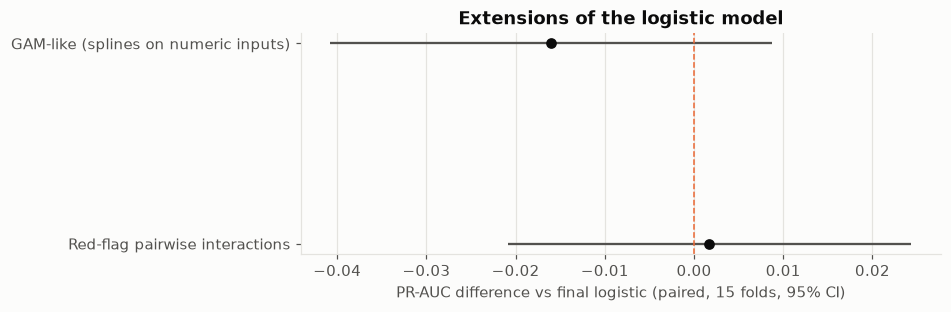

In [2]:
fig, ax = P.plt.subplots(figsize=(7.5, 2.6))
names = [variants[t][0] for t in variants][::-1]
diffs = [tests[t] for t in variants][::-1]
for y, d in enumerate(diffs):
    m, lo, hi = (d[k] for k in ("mean_diff_b_minus_a", "ci_low", "ci_high"))
    ax.errorbar(m, y, xerr=[[m - lo], [hi - m]], fmt="o", color=P.INK, ecolor=P.INK_2, lw=1.5)
ax.axvline(0, color=P.SERIES[1], ls="--", lw=1)
ax.set_yticks(range(len(names)), names)
ax.set_xlabel("PR-AUC difference vs final logistic (paired, 15 folds, 95% CI)")
ax.set_title("Extensions of the logistic model")
ax.grid(axis="y", visible=False)
P.save(fig, "p5_interactions")
P.plt.show()

In [3]:
saved = write_json(
    {
        "preregistration": "notes/00_preregistration.md#A6",
        "data": "dev, 5-fold CV x 3 repeats (same folds as P2); holdout not used",
        "final_pr_auc": metric_ci(final, "pr_auc"),
        "variants": {
            t: {
                "label": variants[t][0],
                "spec": results[t].spec,
                "pr_auc": metric_ci(results[t], "pr_auc"),
                "test": tests[t],
            }
            for t in variants
        },
    },
    "p5_interactions",
)
print("saved", saved.relative_to(C.ROOT))

saved reports/p5_interactions.json


## Summary

In [4]:
def line(t):
    d = tests[t]
    return (
        f"- **{variants[t][0]}:** PR-AUC {metric_ci(results[t], 'pr_auc')['mean']:.3f}, "
        f"difference vs final {d['mean_diff_b_minus_a']:+.3f} [{d['ci_low']:+.3f}, {d['ci_high']:+.3f}], "
        f"better in {d['b_wins_per_folds']} of {d['n_folds']} folds: **{d['verdict']}**."
    )


better = [t for t in variants if tests[t]["verdict"] == "b better"]
if better:
    verdict = (
        "At least one extension beats the final model under the pre-registered rule. It is reported as a lead "
        "for future work; the final model is not changed because the holdout has already been used."
    )
else:
    verdict = (
        "Neither extension beats the plain logistic model under the pre-registered rule. On this dataset the "
        "additive log-odds model is not visibly leaving structure on the table that splines or flag pairs "
        "would capture (within what 271 fraud cases can show)."
    )
display(
    Markdown(f"""
Final logistic pipeline: PR-AUC {metric_ci(final, "pr_auc")["mean"]:.3f} (dev CV, 15 folds).

{line("spline")}
{line("flag_pairs")}

{verdict}
""")
)


Final logistic pipeline: PR-AUC 0.415 (dev CV, 15 folds).

- **GAM-like (splines on numeric inputs):** PR-AUC 0.399, difference vs final -0.016 [-0.041, +0.009], better in 4 of 15 folds: **not distinguishable**.
- **Red-flag pairwise interactions:** PR-AUC 0.417, difference vs final +0.002 [-0.021, +0.024], better in 9 of 15 folds: **not distinguishable**.

Neither extension beats the plain logistic model under the pre-registered rule. On this dataset the additive log-odds model is not visibly leaving structure on the table that splines or flag pairs would capture (within what 271 fraud cases can show).
